In [1]:
#Comparative Analysis of PCA, LDA, and ICA Techniques


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FastICA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, f1_score


data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

# Giving names to the target classes
class_names = ["Malignant", "Benign"]

print("Dataset loaded successfully.")

print("\nFirst five rows:")
display(X.head())

print("\nTarget values:")
print(y.head())

print("\nClass names:")
print(data.target_names)


Dataset loaded successfully.

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target values:
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

Class names:
['malignant' 'benign']


In [2]:
# Checking the size and basic information of the dataset

print("Number of rows and columns:", X.shape)

print("\nNumber of samples:", X.shape[0])
print("Number of input features:", X.shape[1])

print("\nFeature names:")
print(X.columns.tolist())

print("\nMissing values in each column:")
print(X.isnull().sum())

print("\nClass distribution:")
print(y.value_counts().rename(index={0: "Malignant", 1: "Benign"}))

Number of rows and columns: (569, 30)

Number of samples: 569
Number of input features: 30

Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Missing values in each column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension  

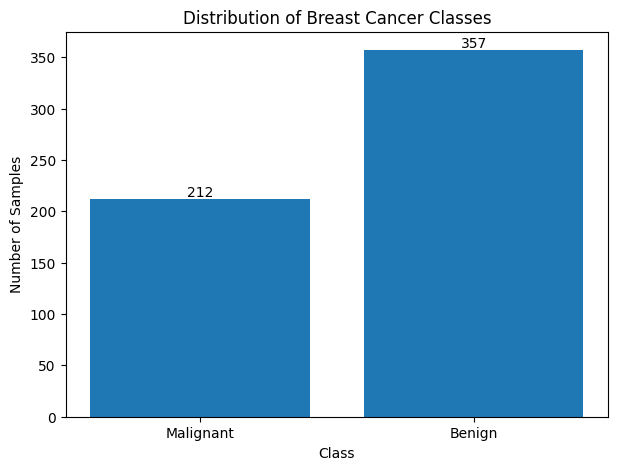

In [3]:
# Checking how many samples belong to each class

class_counts = y.value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(class_names, class_counts.values)

plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

for i, value in enumerate(class_counts.values):
    plt.text(i, value + 3, str(value), ha="center")

plt.show()

In [4]:
# Standardising the features so that they are on a comparable scale

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("Standardisation completed.")

print("\nStandardised data dimensions:", X_scaled.shape)

print("\nFirst five rows after standardisation:")
display(X_scaled.head())

print("\nMean of the first five features:")
print(X_scaled.iloc[:, :5].mean().round(3))

print("\nStandard deviation of the first five features:")
print(X_scaled.iloc[:, :5].std().round(3))

Standardisation completed.

Standardised data dimensions: (569, 30)

First five rows after standardisation:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,...,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,...,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,...,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,...,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,...,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100



Mean of the first five features:
mean radius       -0.0
mean texture      -0.0
mean perimeter    -0.0
mean area         -0.0
mean smoothness    0.0
dtype: float64

Standard deviation of the first five features:
mean radius        1.001
mean texture       1.001
mean perimeter     1.001
mean area          1.001
mean smoothness    1.001
dtype: float64


In [5]:

# Applying PCA to reduce the 30 original features to 2 components

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

print("PCA applied successfully.")

print("\nOriginal dimensions:", X_scaled.shape)
print("Reduced dimensions:", X_pca.shape)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal variance explained by two components:")
print(round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

PCA applied successfully.

Original dimensions: (569, 30)
Reduced dimensions: (569, 2)

Explained variance ratio:
[0.44272026 0.18971182]

Total variance explained by two components:
63.24 %


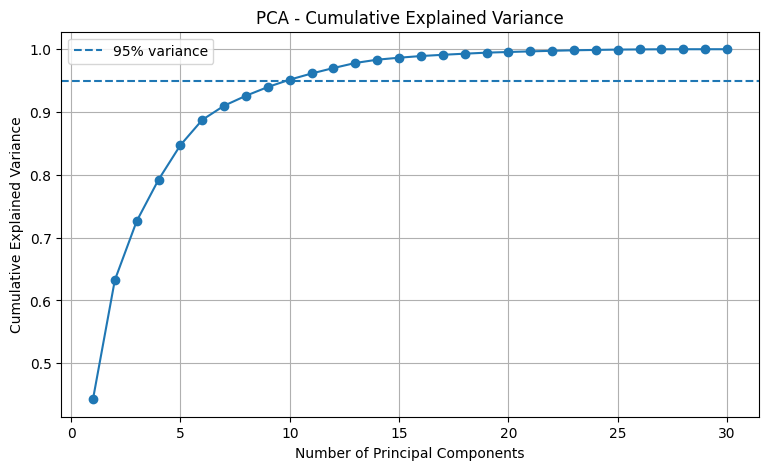

Components required to retain 95% variance: 10
Variance retained: 95.16 %


In [6]:
# Checking how much variance is retained when more components are included

pca_full = PCA()
pca_full.fit(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")

plt.legend()
plt.grid(True)
plt.show()

# Finding how many components are needed to retain at least 95% variance

components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Components required to retain 95% variance:", components_95)
print(
    "Variance retained:",
    round(cumulative_variance[components_95 - 1] * 100, 2),
    "%"
)

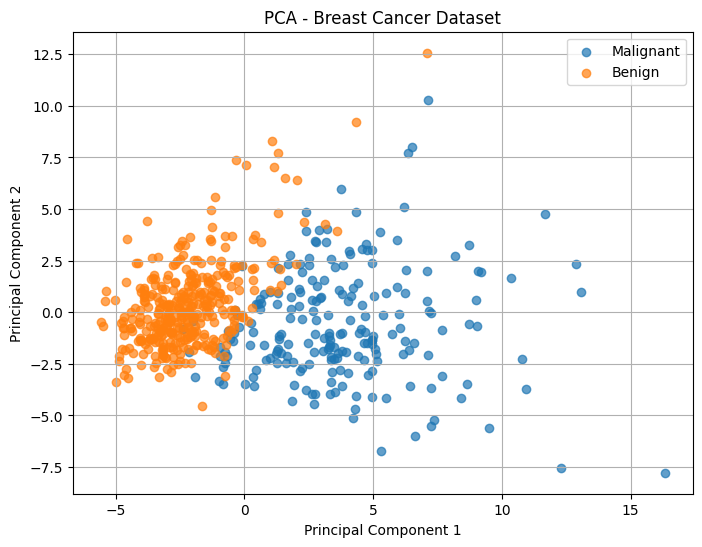

In [7]:
# Visualising the two principal components and their class distribution

plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(class_names):
    plt.scatter(
        pca_df.loc[y == class_id, "PC1"],
        pca_df.loc[y == class_id, "PC2"],
        label=class_name,
        alpha=0.7
    )

plt.title("PCA - Breast Cancer Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(True)
plt.show()

In [8]:
# Applying LDA using the class labels

# Since there are two classes, LDA can produce at most one component

lda = LinearDiscriminantAnalysis(n_components=1)

X_lda = lda.fit_transform(X_scaled, y)

lda_df = pd.DataFrame(
    X_lda,
    columns=["LD1"]
)

print("LDA applied successfully.")

print("\nOriginal dimensions:", X_scaled.shape)
print("Reduced dimensions:", X_lda.shape)

print("\nNumber of discriminant components:", X_lda.shape[1])

LDA applied successfully.

Original dimensions: (569, 30)
Reduced dimensions: (569, 1)

Number of discriminant components: 1


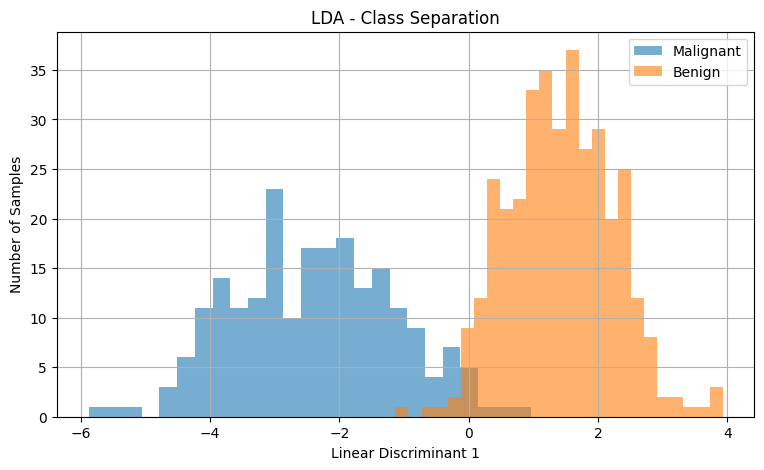

In [9]:
# Plotting the single LDA component for both target classes

plt.figure(figsize=(9, 5))

for class_id, class_name in enumerate(class_names):
    plt.hist(
        lda_df.loc[y == class_id, "LD1"],
        bins=25,
        alpha=0.6,
        label=class_name
    )

plt.title("LDA - Class Separation")
plt.xlabel("Linear Discriminant 1")
plt.ylabel("Number of Samples")

plt.legend()
plt.grid(True)
plt.show()

In [10]:
# Applying ICA to extract two statistically independent components

ica = FastICA(
    n_components=2,
    max_iter=2000,
    tol=0.001,
    random_state=42,
    whiten="unit-variance"
)

X_ica = ica.fit_transform(X_scaled)

ica_df = pd.DataFrame(
    X_ica,
    columns=["IC1", "IC2"]
)

print("ICA applied successfully.")

print("\nOriginal dimensions:", X_scaled.shape)
print("Reduced dimensions:", X_ica.shape)

print("\nICA component dimensions:", ica.components_.shape)

print("\nNumber of independent components:", X_ica.shape[1])

ICA applied successfully.

Original dimensions: (569, 30)
Reduced dimensions: (569, 2)

ICA component dimensions: (2, 30)

Number of independent components: 2


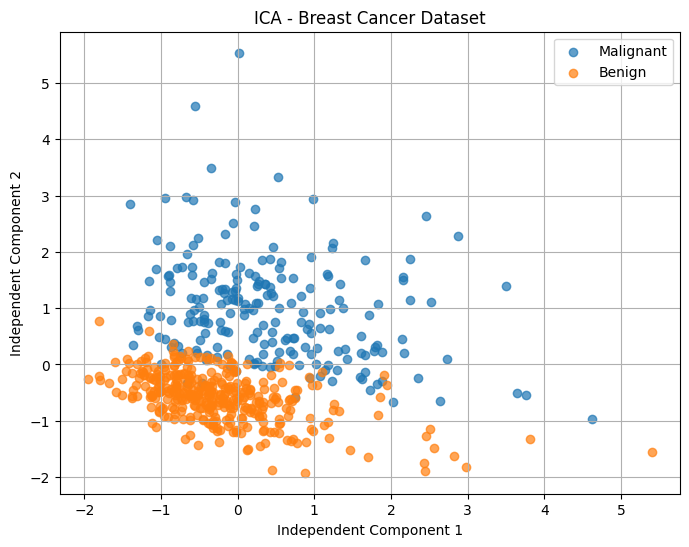

In [11]:
# Visualising the two independent components extracted by ICA

plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(class_names):
    plt.scatter(
        ica_df.loc[y == class_id, "IC1"],
        ica_df.loc[y == class_id, "IC2"],
        label=class_name,
        alpha=0.7
    )

plt.title("ICA - Breast Cancer Dataset")
plt.xlabel("Independent Component 1")
plt.ylabel("Independent Component 2")

plt.legend()
plt.grid(True)
plt.show()

Correlation between ICA components:


,IC1,IC2
IC1,1.0,-0.0
IC2,-0.0,1.0


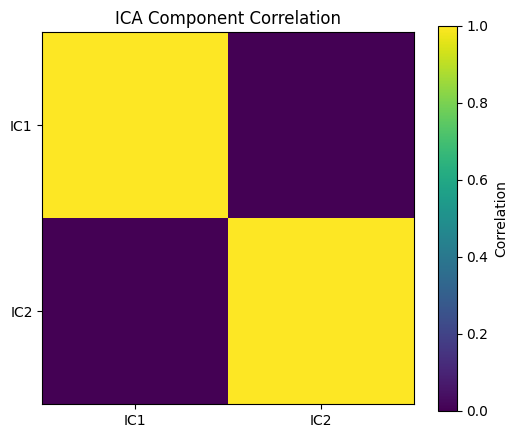

In [12]:
# Checking the correlation between the extracted ICA components

ica_correlation = ica_df.corr()

print("Correlation between ICA components:")
display(ica_correlation.round(4))

plt.figure(figsize=(6, 5))

plt.imshow(ica_correlation, interpolation="nearest")
plt.colorbar(label="Correlation")

plt.xticks([0, 1], ["IC1", "IC2"])
plt.yticks([0, 1], ["IC1", "IC2"])

plt.title("ICA Component Correlation")
plt.show()

In [13]:
# Comparing the original feature count with the reduced dimensions

comparison = pd.DataFrame({
    "Technique": ["Original Dataset", "PCA", "LDA", "ICA"],
    "Original Features": [30, 30, 30, 30],
    "Components Extracted": [
        30,
        X_pca.shape[1],
        X_lda.shape[1],
        X_ica.shape[1]
    ]
})

print("Component comparison:")
display(comparison)

Component comparison:


,Technique,Original Features,Components Extracted
0,Original Dataset,30,30
1,PCA,30,2
2,LDA,30,1
3,ICA,30,2


In [14]:
# Comparing the classification performance of the three techniques

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Original Features": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),

    "PCA": Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=2)),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),

    "LDA": Pipeline([
        ("scaler", StandardScaler()),
        ("lda", LinearDiscriminantAnalysis(n_components=1)),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),

    "ICA": Pipeline([
        ("scaler", StandardScaler()),
        ("ica", FastICA(
            n_components=2,
            max_iter=2000,
            tol=0.001,
            random_state=42,
            whiten="unit-variance"
        )),
        ("classifier", LogisticRegression(max_iter=2000))
    ])
}

evaluation_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=["accuracy", "f1_macro"]
    )

    evaluation_results.append({
        "Technique": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Mean F1 Score": scores["test_f1_macro"].mean()
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("Five-fold cross-validation results:")
display(evaluation_df.round(4))

Five-fold cross-validation results:


,Technique,Mean Accuracy,Accuracy Std,Mean F1 Score
0,Original Features,0.9737,0.0166,0.9714
1,PCA,0.9473,0.0241,0.9433
2,LDA,0.9684,0.0212,0.9655
3,ICA,0.9403,0.0187,0.9353


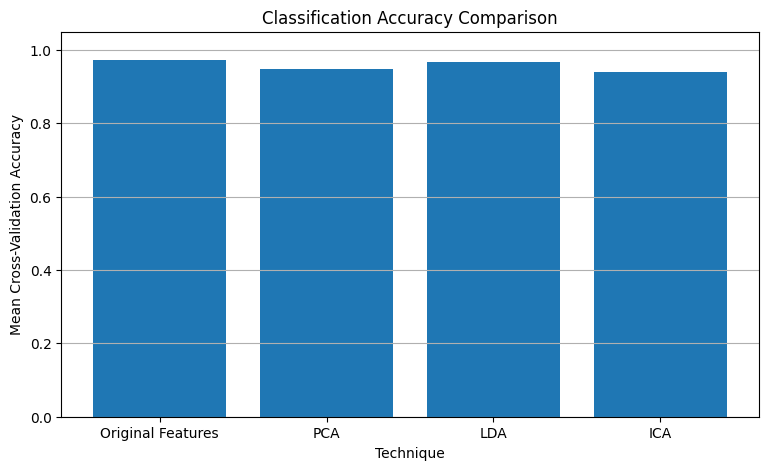

In [15]:
# Comparing the average classification accuracy of each technique

plt.figure(figsize=(9, 5))

plt.bar(
    evaluation_df["Technique"],
    evaluation_df["Mean Accuracy"]
)

plt.title("Classification Accuracy Comparison")
plt.xlabel("Technique")
plt.ylabel("Mean Cross-Validation Accuracy")

plt.ylim(0, 1.05)
plt.grid(axis="y")
plt.show()

In [16]:
# Studying the effect of different component counts on model performance

component_counts = [2, 5, 10, 15, 20]

self_learning_results = []

# Testing PCA with different numbers of components
for n in component_counts:

    pca_model = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n)),
        ("classifier", LogisticRegression(max_iter=2000))
    ])

    scores = cross_validate(
        pca_model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    self_learning_results.append({
        "Technique": "PCA",
        "Number of Components": n,
        "Mean Accuracy": scores["test_score"].mean()
    })


# Testing ICA with different numbers of components
for n in component_counts:

    ica_model = Pipeline([
        ("scaler", StandardScaler()),
        ("ica", FastICA(
            n_components=n,
            max_iter=2000,
            tol=0.001,
            random_state=42,
            whiten="unit-variance"
        )),
        ("classifier", LogisticRegression(max_iter=2000))
    ])

    scores = cross_validate(
        ica_model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    self_learning_results.append({
        "Technique": "ICA",
        "Number of Components": n,
        "Mean Accuracy": scores["test_score"].mean()
    })


self_learning_df = pd.DataFrame(self_learning_results)

print("Self-learning experiment results:")
display(self_learning_df.round(4))

Self-learning experiment results:


,Technique,Number of Components,Mean Accuracy
0,PCA,2,0.9473
1,PCA,5,0.9631
2,PCA,10,0.9772
3,PCA,15,0.9737
4,PCA,20,0.9754
5,ICA,2,0.9403
6,ICA,5,0.9666
7,ICA,10,0.9754
8,ICA,15,0.9684
9,ICA,20,0.9702


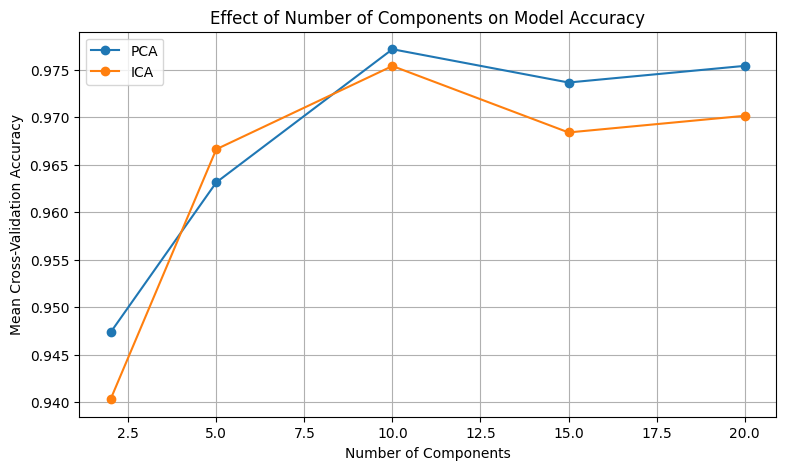

In [17]:
# Plotting how the number of components affects classification accuracy

plt.figure(figsize=(9, 5))

for technique in ["PCA", "ICA"]:

    result = self_learning_df[
        self_learning_df["Technique"] == technique
    ]

    plt.plot(
        result["Number of Components"],
        result["Mean Accuracy"],
        marker="o",
        label=technique
    )

plt.title("Effect of Number of Components on Model Accuracy")
plt.xlabel("Number of Components")
plt.ylabel("Mean Cross-Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [18]:
# Preparing a summary of the three dimensionality reduction techniques

pca_variance = pca.explained_variance_ratio_.sum() * 100

ica_corr = abs(
    ica_df.corr().iloc[0, 1]
)

final_comparison = pd.DataFrame({
    "Parameter": [
        "Approach",
        "Uses Class Labels",
        "Components for Visualisation",
        "Main Objective",
        "PCA Variance Retained",
        "Class Separation",
        "Independent Components"
    ],

    "PCA": [
        "Unsupervised",
        "No",
        2,
        "Maximum variance",
        f"{pca_variance:.2f}%",
        "Not directly optimised",
        "Not applicable"
    ],

    "LDA": [
        "Supervised",
        "Yes",
        X_lda.shape[1],
        "Maximum class separation",
        "Not applicable",
        "Evaluated using cross-validation",
        "Not applicable"
    ],

    "ICA": [
        "Unsupervised",
        "No",
        X_ica.shape[1],
        "Statistical independence",
        "Not applicable",
        "Not directly optimised",
        f"Absolute component correlation: {ica_corr:.4f}"
    ]
})

print("Final comparison of PCA, LDA and ICA:")
display(final_comparison)

Final comparison of PCA, LDA and ICA:


,Parameter,PCA,LDA,ICA
0,Approach,Unsupervised,Supervised,Unsupervised
1,Uses Class Labels,No,Yes,No
2,Components for Visualisation,2,1,2
3,Main Objective,Maximum variance,Maximum class separation,Statistical independence
4,PCA Variance Retained,63.24%,Not applicable,Not applicable
5,Class Separation,Not directly optimised,Evaluated using cross-validation,Not directly optimised
6,Independent Components,Not applicable,Not applicable,Absolute component correlation: 0.0000


In [19]:
# Identifying the technique with the highest mean cross-validation accuracy

best_result = evaluation_df.loc[
    evaluation_df["Mean Accuracy"].idxmax()
]

print("Best performing technique in this comparison:")
print(best_result["Technique"])

print(
    "Mean Accuracy:",
    round(best_result["Mean Accuracy"] * 100, 2),
    "%"
)

print(
    "Mean F1 Score:",
    round(best_result["Mean F1 Score"], 4)
)

Best performing technique in this comparison:
Original Features
Mean Accuracy: 97.37 %
Mean F1 Score: 0.9714


## Analysis and Discussion

### 1. What is dimensionality reduction, and why is it important?

Dimensionality reduction is the process of reducing the number of input variables or features in a dataset while retaining useful information. It helps simplify data, reduce computational complexity, remove redundancy and make visualisation easier.

### 2. Explain the fundamental differences between PCA, LDA and ICA.

PCA is an unsupervised technique that identifies directions of maximum variance. LDA is a supervised technique that uses class labels to maximise separation between classes. ICA is an unsupervised technique that attempts to extract statistically independent components.

### 3. Why does PCA focus on maximum variance rather than class separation?

PCA does not use target labels. Its objective is to preserve as much variation in the original data as possible, regardless of whether that variation separates the classes.

### 4. How does LDA utilise class labels?

LDA uses the known class labels to calculate within-class and between-class scatter. It finds directions that maximise the separation between classes while minimising variation within each class.

### 5. Why does ICA attempt to identify statistically independent components?

ICA assumes that the observed data may contain combinations of underlying independent sources. It attempts to separate these sources based on statistical independence.

### 6. Which technique provides better class separation?

LDA is specifically designed to maximise class separation, so it is expected to provide good class separation for labelled data. The cross-validation results and LDA visualisation help evaluate its practical performance on this dataset.

### 7. Real-world applications

- PCA: Image compression, data visualisation, noise reduction and preprocessing of high-dimensional data.
- LDA: Medical diagnosis, face recognition and classification problems.
- ICA: Biomedical signal processing, EEG analysis, audio source separation and separating mixed signals.

## Overall Conclusion

In this experiment, PCA, LDA and ICA were implemented using the Breast Cancer Wisconsin dataset.

The original 30 features were standardised before applying the three techniques. PCA was used to identify components that retain maximum variance, LDA used class labels to find discriminant components, and ICA extracted statistically independent components.

The transformed datasets were visualised and compared. Cross-validation was also used to evaluate their classification performance. The additional experiment examined how changing the number of components affects model accuracy.

The experiment demonstrated that each dimensionality reduction technique has a different objective and that the most suitable method depends on the dataset and the intended application.

In [20]:
# Displaying the main dimensions and results from the experiment

print("FINAL LAB SUMMARY")

print("Dataset: Breast Cancer Wisconsin")

print("Original dataset dimensions:", X.shape)

print("PCA dimensions:", X_pca.shape)
print("LDA dimensions:", X_lda.shape)
print("ICA dimensions:", X_ica.shape)

print(
    "PCA variance retained by 2 components:",
    round(pca_variance, 2),
    "%"
)

print(
    "Components required for 95% PCA variance:",
    components_95
)

print("\nClassification comparison:")
display(
    evaluation_df[
        ["Technique", "Mean Accuracy", "Mean F1 Score"]
    ].round(4)
)

print("\nLab Exercise 4 completed.")

FINAL LAB SUMMARY
Dataset: Breast Cancer Wisconsin
Original dataset dimensions: (569, 30)
PCA dimensions: (569, 2)
LDA dimensions: (569, 1)
ICA dimensions: (569, 2)
PCA variance retained by 2 components: 63.24 %
Components required for 95% PCA variance: 10

Classification comparison:


,Technique,Mean Accuracy,Mean F1 Score
0,Original Features,0.9737,0.9714
1,PCA,0.9473,0.9433
2,LDA,0.9684,0.9655
3,ICA,0.9403,0.9353



Lab Exercise 4 completed.
